# Parts 6–7 — Comparison of approaches, robustness to scale, failures, ensemble

Hypotheses for Blocks 6a/6b/7 were committed before this notebook was run (`HYPOTHESES.md`).
All numbers are site-grouped 5-fold CV EMD (lower is better) read from `experiments/*/metrics.json`;
Kaggle scores come from `reports/leaderboard.csv` (filled after submitting).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from soilgs import paths
from soilgs.experiment import fold_scores, results_table
from soilgs.interpret import load_trained, sample_curves, emd_of, at_resolution, with_scale_error
from soilgs.metric import COLS, emd_per_sample
from soilgs.submission import write_submission
from soilgs.train import Data, get_device

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
device = get_device()
data = Data.load()
labels, folds, photos = data.labels, data.folds, data.photos
lab = labels.set_index("sample_id")
fold_of = folds.set_index("sample_id").fold
group = pd.cut(lab["2"], [-1, 60, 90, 101], labels=["gravelly", "mixed", "fine"])
res = results_table().set_index("name")
lb_path = paths.ROOT / "reports" / "leaderboard.csv"
lb = pd.read_csv(lb_path).set_index("submission") if lb_path.exists() else pd.DataFrame(columns=["public_lb", "private_lb"])

def metrics(name):
    return json.loads((paths.EXPERIMENTS / name / "metrics.json").read_text())

def oof(name):
    return pd.read_csv(paths.EXPERIMENTS / name / "oof.csv", index_col=0)

/home/v.moisieiev/Documents/GitHub/cv_1_assignment/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. One comparison table — the best configuration of each approach
Seed std: replicate runs with seeds 1–2 (where available). Data efficiency: same recipe trained on
50 % / 75 % of each fold's training samples. GPU-hours are for the whole 5-fold run.

In [2]:
FAMILIES = {
    "hand-crafted texture + ridge (Part 0)": ("p0_texture_ridge_50mm", None, None),
    "CNN: ResNet-18 SGD (Part 1)": ("p1_r18_sgd", "rep_p1_r18_sgd", "p6_r18_sgd"),
    "ViT: own ViT from scratch (Part 2)": ("p2_tinyvit_scratch", "rep_p2_tinyvit_scratch", "p6_tinyvit"),
    "ViT: pretrained ViT-S, nested early stop (Part 2)": ("p2_vits_nested", None, None),
    "SSL: DINOv3-S fine-tuned (Part 3)": ("p3_dinov3_s_ft", "rep_p3_dinov3_s_ft", "p6_dinov3_s_ft"),
    "SSL: MAE-B LP-FT (Part 3)": ("p3_mae_b_lpft", None, None),
    "SSL: DINOv2-S frozen, 100 mm (Part 3)": ("p3_dinov2_s_ctx100_frozen_ridge", None, None),
}
rows = []
for fam, (name, rep, eff) in FAMILIES.items():
    m = metrics(name)
    seeds = [m["cv_mean"]] + [metrics(f"{rep}_s{i}")["cv_mean"] for i in (1, 2)
                              if rep and (paths.EXPERIMENTS / f"{rep}_s{i}").exists()]
    row = {"approach": fam, "experiment": name, "CV": f"{m['cv_mean']:.1f} ± {m['cv_std']:.1f}",
           "seed mean ± std": f"{np.mean(seeds):.1f} ± {np.std(seeds):.1f} (n={len(seeds)})" if len(seeds) > 1 else "",
           "75 % data": metrics(f"{eff}_frac75")["cv_mean"] if eff and (paths.EXPERIMENTS / f"{eff}_frac75").exists() else np.nan,
           "50 % data": metrics(f"{eff}_frac50")["cv_mean"] if eff and (paths.EXPERIMENTS / f"{eff}_frac50").exists() else np.nan,
           "GPU-h": m["compute"].get("gpu_hours", 0), "peak GB": m["compute"].get("peak_mem_gb", np.nan),
           "device": m["compute"].get("device", "")}
    rows.append(row)
comparison = pd.DataFrame(rows).set_index("approach")
display(comparison.round(2))

,experiment,CV,seed mean ± std,75 % data,50 % data,GPU-h,peak GB,device
approach,,,,,,,,
hand-crafted texture + ridge (Part 0),p0_texture_ridge_50mm,38.2 ± 14.6,,NaN,NaN,0.00,0.00,NVIDIA GeForce RTX 5070 Laptop GPU
CNN: ResNet-18 SGD (Part 1),p1_r18_sgd,37.9 ± 15.1,,45.37,40.66,0.09,0.62,NVIDIA GeForce RTX 5070 Laptop GPU
ViT: own ViT from scratch (Part 2),p2_tinyvit_scratch,36.4 ± 14.7,37.4 ± 0.7 (n=3),45.88,45.34,0.09,0.39,NVIDIA A100-SXM4-40GB
"ViT: pretrained ViT-S, nested early stop (Part 2)",p2_vits_nested,39.6 ± 14.9,,NaN,NaN,0.70,1.72,NVIDIA A100-SXM4-40GB
SSL: DINOv3-S fine-tuned (Part 3),p3_dinov3_s_ft,42.2 ± 17.0,41.9 ± 0.2 (n=3),48.63,48.61,0.49,1.85,NVIDIA L4
SSL: MAE-B LP-FT (Part 3),p3_mae_b_lpft,40.9 ± 15.3,,NaN,NaN,0.88,3.75,NVIDIA L4
"SSL: DINOv2-S frozen, 100 mm (Part 3)",p3_dinov2_s_ctx100_frozen_ridge,42.3 ± 15.9,,NaN,NaN,0.00,0.00,NVIDIA GeForce RTX 5070 Laptop GPU


## 2. Robustness to scale (Block 6b)
Held-out photos of each fold, through that fold's model:
* **lower resolution, correct px/mm**: the same photo as if taken at ×0.75 / ×0.5 / ×0.35 of
  4.5 px/mm (detail lost, then resampled back by the pipeline);
* **wrong px/mm**: the photo resampled as if its scale were mis-stated by ×0.8 / ×1.25.

model               ResNet-18 SGD  ViT-S  scratch ViT
kind        factor                                   
resolution  0.35             39.8   41.5         35.0
            0.50             35.1   43.1         35.0
            0.75             35.0   44.2         35.1
            1.00             34.8   44.4         35.1
scale error 0.80             35.6   43.5         35.2
            1.25             35.8   45.2         35.8

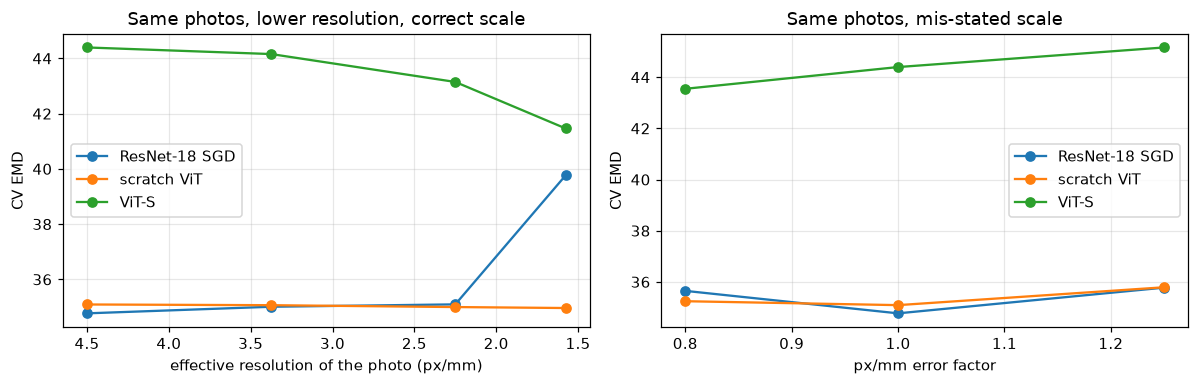

In [3]:
FINAL = {"ResNet-18 SGD": "final_r18_sgd", "scratch ViT": "final_tinyvit_scratch", "ViT-S": "final_vits"}
train_imgs = {s: [data.images[p] for p in photos[(photos.sample_id == s) & (photos.split == "train")].photo_id] for s in lab.index}
perturb = {("resolution", f): (lambda im, f=f: at_resolution(im, f)) for f in (1.0, 0.75, 0.5, 0.35)}
perturb.update({("scale error", f): (lambda im, f=f: with_scale_error(im, f)) for f in (0.8, 1.25)})
rob, photo_rows = [], []
for title, name in FINAL.items():
    for k in sorted(fold_of.unique()):
        model, cfg, mean, std = load_trained(name, int(k), device)
        ids = fold_of.index[fold_of == k]
        for (kind, f), fn in perturb.items():
            e = emd_of(sample_curves(model, {s: [fn(im) for im in train_imgs[s]] for s in ids}, cfg, mean, std, device), labels)
            rob += [{"model": title, "kind": kind, "factor": f, "sample": s, "emd": v} for s, v in e.items()]
        for r in photos[photos.sample_id.isin(ids) & (photos.split == "train")].itertuples():  # per-photo, for devices
            e = emd_of(sample_curves(model, {r.sample_id: [data.images[r.photo_id]]}, cfg, mean, std, device), labels)
            photo_rows.append({"model": title, "camera": r.camera, "sample": r.sample_id, "emd": float(e.iloc[0])})
        del model; torch.cuda.empty_cache()
rob = pd.DataFrame(rob)
rob_table = rob.groupby(["kind", "factor", "model"]).emd.mean().unstack()
display(rob_table.round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for title in FINAL:
    r = rob_table[title].loc["resolution"]
    ax[0].plot(r.index * 4.5, r.values, "o-", label=title)
    s = rob_table[title].loc["scale error"]
    ax[1].plot([0.8, 1.0, 1.25], [s.loc[0.8], rob_table[title].loc[("resolution", 1.0)], s.loc[1.25]], "o-", label=title)
ax[0].set(xlabel="effective resolution of the photo (px/mm)", ylabel="CV EMD", title="Same photos, lower resolution, correct scale")
ax[0].invert_xaxis(); ax[0].legend()
ax[1].set(xlabel="px/mm error factor", ylabel="CV EMD", title="Same photos, mis-stated scale"); ax[1].legend()
plt.tight_layout(); plt.savefig(paths.ROOT / "reports" / "fig_scale_robustness.png", dpi=110); plt.show()
rob.to_csv(paths.ROOT / "reports" / "scale_robustness.csv", index=False)

## 3. Where does each approach fail? (fine vs coarse soils, devices)

In [4]:
names = {fam.split(" (")[0]: v[0] for fam, v in FAMILIES.items()}
per_sample = pd.DataFrame({k: oof(v).emd for k, v in names.items()})
by_group = per_sample.groupby(group[per_sample.index]).mean().T
by_group["n samples"] = ""
display(by_group.round(1))
dev = pd.DataFrame(photo_rows).groupby(["model", "camera"]).emd.agg(["mean", "count"]).unstack(0)
display(dev.round(1))
display(per_sample.assign(group=group).sort_values("CNN: ResNet-18 SGD", ascending=False).head(6).round(1))

2,gravelly,mixed,fine,n samples
hand-crafted texture + ridge,31.3,89.5,38.2,
CNN: ResNet-18 SGD,32.7,87.1,36.0,
ViT: own ViT from scratch,32.2,86.6,33.1,
"ViT: pretrained ViT-S, nested early stop",34.1,88.8,40.2,
SSL: DINOv3-S fine-tuned,34.1,102.5,43.3,
SSL: MAE-B LP-FT,33.9,101.2,40.4,
"SSL: DINOv2-S frozen, 100 mm",34.1,87.6,43.6,


mean                           count        \
model                   ResNet-18 SGD ViT-S scratch ViT ResNet-18 SGD ViT-S   
camera                                                                        
Motorola Edge                    36.8  44.4        32.9            69    69   
Motorola Edge 60 Fusion          32.9  29.3        46.9             3     3   
Samsung A52                      40.5  50.0        42.7            55    55   

                                     
model                   scratch ViT  
camera                               
Motorola Edge                    69  
Motorola Edge 60 Fusion           3  
Samsung A52                      55

,hand-crafted texture + ridge,CNN: ResNet-18 SGD,ViT: own ViT from scratch,"ViT: pretrained ViT-S, nested early stop",SSL: DINOv3-S fine-tuned,SSL: MAE-B LP-FT,"SSL: DINOv2-S frozen, 100 mm",group
H038,122.5,119.9,113.7,123.4,142.6,132.3,140.8,gravelly
H037,89.5,87.1,86.6,88.8,102.5,101.2,87.6,mixed
H616,75.0,81.0,74.1,65.4,72.3,81.1,75.5,fine
H666,49.2,60.2,36.8,27.7,32.8,58.6,47.7,fine
H516,38.2,51.8,56.6,46.3,44.0,50.1,45.4,gravelly
H405,54.0,50.2,24.9,91.9,117.9,90.2,95.6,fine


## 4. Ensemble (Part 7)
Members must have both OOF curves (for CV) and test curves (for submission). Correlation of
per-sample OOF errors first: diversity, not just the best scores.

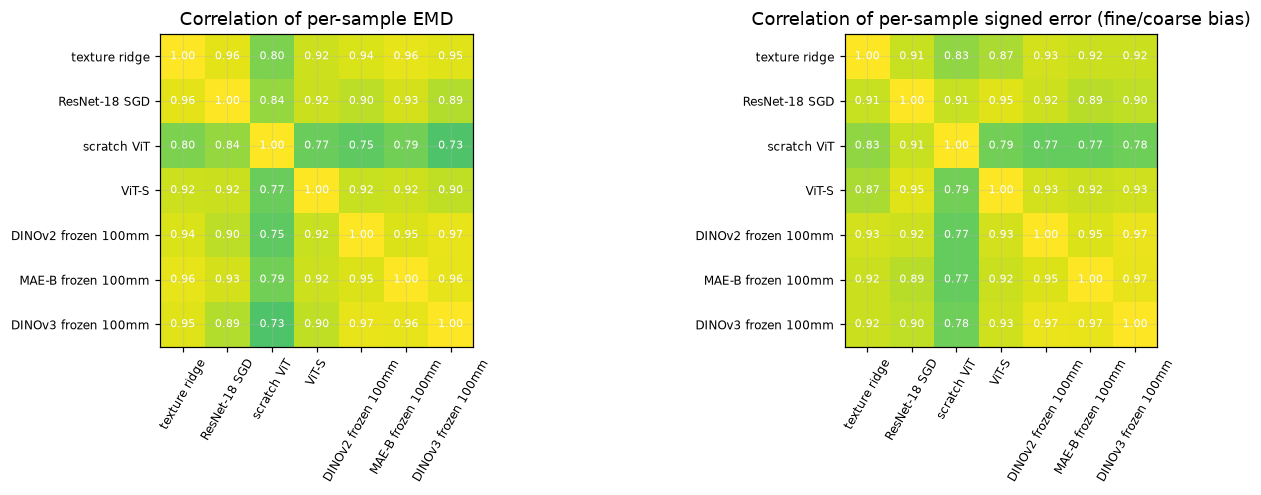

,CV,std
ensemble,,
"greedy on OOF (optimistic): ['ResNet-18 SGD', 'scratch ViT', 'texture ridge']",35.75,15.37
two best singles,36.11,14.69
"diverse, pre-declared (texture, ResNet-18, scratch ViT, DINOv2 frozen)",36.39,15.54
single: ResNet-18 SGD,36.51,14.88
single: scratch ViT,36.55,14.77
single: texture ridge,38.17,14.63
"trained nets only (ResNet-18, scratch ViT, ViT-S)",38.81,15.91
all candidates,39.65,16.23
single: DINOv2 frozen 100mm,42.27,15.92


In [5]:
CAND = {"texture ridge": "p0_texture_ridge_50mm", "ResNet-18 SGD": "final_r18_sgd", "scratch ViT": "final_tinyvit_scratch",
        "ViT-S": "final_vits", "DINOv2 frozen 100mm": "p3_dinov2_s_ctx100_frozen_ridge",
        "MAE-B frozen 100mm": "p3_mae_b_ctx100_frozen_ridge", "DINOv3 frozen 100mm": "p3_dinov3_s_ctx100_frozen_ridge"}
CAND = {k: v for k, v in CAND.items() if (paths.ROOT / "submissions" / f"{v}.csv").exists()}
O = {k: oof(v)[COLS].loc[lab.index] for k, v in CAND.items()}
Y = lab[COLS].to_numpy(float)
err = pd.DataFrame({k: emd_per_sample(Y, o.to_numpy()) for k, o in O.items()}, index=lab.index)
bias = pd.DataFrame({k: (o.to_numpy() - Y)[:, :-1].mean(1) for k, o in O.items()}, index=lab.index)  # >0: predicted too fine
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, M, t in ((ax[0], err.corr(), "per-sample EMD"), (ax[1], bias.corr(), "per-sample signed error (fine/coarse bias)")):
    im = a.imshow(M, vmin=0, vmax=1, cmap="viridis"); a.set_xticks(range(len(M)), M.columns, rotation=60, fontsize=8)
    a.set_yticks(range(len(M)), M.index, fontsize=8); a.set_title(f"Correlation of {t}")
    for i in range(len(M)):
        for j in range(len(M)):
            a.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
plt.tight_layout(); plt.savefig(paths.ROOT / "reports" / "fig_error_correlation.png", dpi=110); plt.show()

def score(members):
    P = np.mean([O[m].to_numpy() for m in members], 0)
    _, pf = fold_scores(pd.DataFrame(P, index=lab.index, columns=COLS), labels, folds)
    return pf.mean(), pf.std(ddof=0)

single = {k: score([k]) for k in O}
best_single = min(single, key=lambda k: single[k][0])
ENSEMBLES = {
    "diverse, pre-declared (texture, ResNet-18, scratch ViT, DINOv2 frozen)": ["texture ridge", "ResNet-18 SGD", "scratch ViT", "DINOv2 frozen 100mm"],
    "trained nets only (ResNet-18, scratch ViT, ViT-S)": ["ResNet-18 SGD", "scratch ViT", "ViT-S"],
    "two best singles": sorted(single, key=lambda k: single[k][0])[:2],
    "all candidates": list(O),
}
rows = [{"ensemble": f"single: {k}", "CV": v[0], "std": v[1]} for k, v in single.items()]
rows += [{"ensemble": k, "CV": score([m for m in v if m in O])[0], "std": score([m for m in v if m in O])[1]} for k, v in ENSEMBLES.items()]
# Greedy forward selection (Caruana) on the same OOF — optimistic, reported for comparison only.
chosen, best = [], np.inf
while True:
    trial = {k: score(chosen + [k])[0] for k in O}
    k = min(trial, key=trial.get)
    if trial[k] >= best - 1e-6 or len(chosen) >= 8:
        break
    chosen.append(k); best = trial[k]
rows.append({"ensemble": f"greedy on OOF (optimistic): {chosen}", "CV": score(chosen)[0], "std": score(chosen)[1]})
ens = pd.DataFrame(rows).set_index("ensemble")
display(ens.sort_values("CV").round(2))

**Final submission = chosen by CV, among models/ensembles decided *before* looking at the leaderboard:**
the pre-declared diverse ensemble if its CV beats the best single model, otherwise the best single model.

In [6]:
diverse = ENSEMBLES["diverse, pre-declared (texture, ResNet-18, scratch ViT, DINOv2 frozen)"]
diverse = [m for m in diverse if m in O]
use = diverse if score(diverse)[0] < single[best_single][0] else [best_single]
test = np.mean([pd.read_csv(paths.ROOT / "submissions" / f"{CAND[m]}.csv").set_index("sample_id")[COLS].to_numpy(float) for m in use], 0)
ids = pd.read_csv(paths.ROOT / "submissions" / f"{CAND[use[0]]}.csv").sample_id
final = write_submission(pd.DataFrame(test, index=ids, columns=COLS), paths.ROOT / "submissions" / "final_ensemble.csv")
print("final submission members:", use, f"-> CV {score(use)[0]:.2f}")
display(final.round(1))

final submission members: ['texture ridge', 'ResNet-18 SGD', 'scratch ViT', 'DINOv2 frozen 100mm'] -> CV 36.39


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,HPC_Airbus BS6-3,1.6,3.6,9.9,38.5,72.2,81.2,87.6,94.8,98.2,99.8,100.0
1,HPC_Audorfring,0.9,2.5,5.8,15.9,29.3,41.1,58.6,80.5,93.3,99.4,100.0
2,HPC_Muenster_BS6_9_0-10m,1.3,2.7,6.1,15.0,25.2,34.9,46.6,66.1,87.4,99.5,100.0
3,HPC_Airbus BS10-4bis7,1.6,3.8,10.5,40.3,74.3,82.3,88.2,95.0,98.3,99.8,100.0
4,HPC_Airbus BS12-5bis8,2.1,4.7,12.4,42.2,74.7,82.7,88.1,94.5,98.1,99.7,100.0
5,HPC_Kleinkummerfeld 2-2,1.7,3.7,10.2,37.6,72.5,82.9,89.5,96.3,98.7,99.8,100.0
6,HPC_Kleinkummerfeld 2-3,1.7,3.6,10.3,39.5,75.6,84.6,90.4,96.3,98.7,99.8,100.0
7,HPC_Kleinkummerfeld 9-4,1.6,3.6,9.8,36.5,68.5,77.3,84.9,93.8,98.1,99.8,100.0
8,HPC_Kleinkummerfeld 18-3,1.6,3.6,9.9,38.2,71.9,80.2,87.2,95.1,98.5,99.8,100.0
9,HPC_Testfeld Lidl WHV,0.8,1.8,4.1,9.8,15.6,22.7,38.6,63.7,88.6,99.4,100.0


### Extrapolation guard (H6c) on top of the final submission
The leave-coarsest-out check (H6c, `scripts/check_guard.py`) cleared the pre-declared bar, so the guard is
applied: it changes only test samples whose texture-scale centroid lies beyond the training range.

In [7]:
from soilgs.baselines import tile_feature_table
from soilgs.guard import Guard

tiles = tile_feature_table(photos, 50)
cent = tiles.groupby(["split", "sample_id"]).dog_centroid.mean()
guard = Guard().fit(cent.loc["train"].to_numpy(), lab.loc[cent.loc["train"].index, COLS].to_numpy(float))
test_c = cent.loc["test"].loc[ids].to_numpy()
guarded, w = guard.apply(test_c, test)
print("guard weight per test sample:", dict(zip(ids, w.round(2))))
final_g = write_submission(pd.DataFrame(guarded, index=ids, columns=COLS), paths.ROOT / "submissions" / "final_ensemble_guard.csv")
display(final_g[w > 0].round(1))

guard weight per test sample: {'HPC_Airbus BS6-3': np.float64(0.0), 'HPC_Audorfring': np.float64(0.0), 'HPC_Muenster_BS6_9_0-10m': np.float64(1.0), 'HPC_Airbus BS10-4bis7': np.float64(0.0), 'HPC_Airbus BS12-5bis8': np.float64(0.0), 'HPC_Kleinkummerfeld 2-2': np.float64(0.0), 'HPC_Kleinkummerfeld 2-3': np.float64(0.0), 'HPC_Kleinkummerfeld 9-4': np.float64(0.0), 'HPC_Kleinkummerfeld 18-3': np.float64(0.0), 'HPC_Testfeld Lidl WHV': np.float64(0.0)}


,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
2,HPC_Muenster_BS6_9_0-10m,0.6,1.1,1.6,2.5,4.5,6.8,9.2,13.2,17.9,26.0,100.0
